# Tugas 3 — Praktik Recipes dari Buku dan Recipe Buatan Sendiri

**Nama:** Abdussalam Said Al Mubarak
**NIM:** H061241027
**Mata kuliah:** Kecerdasan AI Geofisika  

Notebook ini mempraktikkan satu recipe dari buku *AI Cookbook untuk Earth Sciences* dan mengembangkan satu recipe sederhana yang berbeda. Contoh memakai **data curah hujan sintetis**, sehingga dapat dijalankan tanpa mengunduh data eksternal.

**Alur kerja:** Problem → Input → Code → Result → Check.

## 1. Recipe dari buku: R-VIS-001 — Membuat Time-Series Figure yang Informatif

Recipe pada buku ini membahas pembuatan grafik deret waktu yang informatif. Dalam praktik ini, kita akan memvisualisasikan curah hujan bulanan selama dua tahun.

**Tujuan:** membuat grafik dengan judul, label sumbu, unit, dan grid agar pola data mudah dibaca.  
**Input:** data curah hujan bulanan sintetis (mm/bulan).  
**Output yang diharapkan:** grafik deret waktu dan ringkasan nilai minimum, maksimum, serta rata-rata.  
**Batasan:** data hanya untuk demonstrasi, bukan observasi meteorologi nyata.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Data sintetis: curah hujan bulanan selama 2024–2025 (mm/bulan)
data_hujan = {
    "bulan": pd.date_range("2024-01-01", periods=24, freq="MS"),
    "curah_hujan_mm": [
        280, 250, 220, 180, 130, 90, 70, 60, 85, 150, 230, 300,
        290, 260, 210, 170, 120, 80, 55, 65, 100, 165, 245, 310
    ]
}
df = pd.DataFrame(data_hujan)
df.head()

,bulan,curah_hujan_mm
0,2024-01-01,280
1,2024-02-01,250
2,2024-03-01,220
3,2024-04-01,180
4,2024-05-01,130


### 1.1 Membuat grafik deret waktu

Grafik digunakan untuk melihat perubahan curah hujan dari bulan ke bulan. Pastikan label sumbu mencantumkan variabel dan unit.

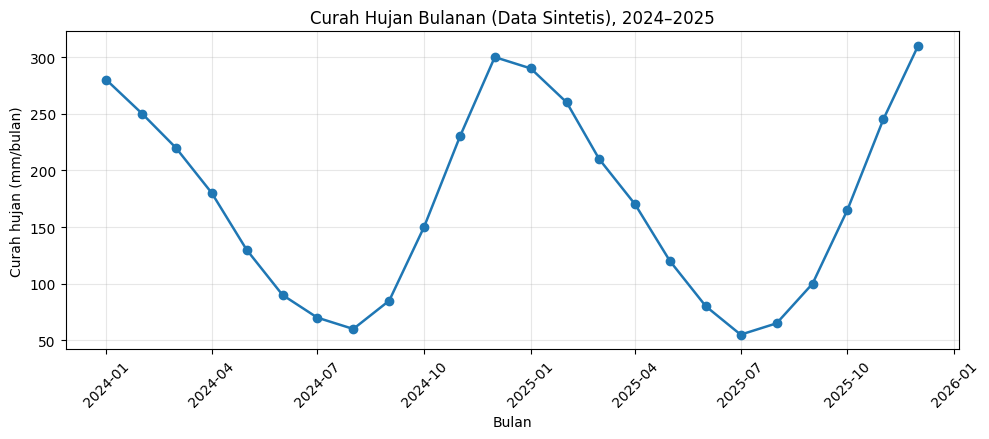

Jumlah data: 24
Minimum (mm/bulan): 55
Maksimum (mm/bulan): 310
Rata-rata (mm/bulan): 171.46


In [2]:
plt.figure(figsize=(10, 4.5))
plt.plot(df["bulan"], df["curah_hujan_mm"], marker="o", linewidth=1.8)
plt.title("Curah Hujan Bulanan (Data Sintetis), 2024–2025")
plt.xlabel("Bulan")
plt.ylabel("Curah hujan (mm/bulan)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Jumlah data:", len(df))
print("Minimum (mm/bulan):", df["curah_hujan_mm"].min())
print("Maksimum (mm/bulan):", df["curah_hujan_mm"].max())
print("Rata-rata (mm/bulan):", round(df["curah_hujan_mm"].mean(), 2))

### 1.2 Check sederhana

Periksa bahwa tanggal dan nilai hujan tersedia, tidak ada nilai kosong, dan curah hujan tidak negatif.

In [3]:
assert df["bulan"].notna().all(), "Ada tanggal yang kosong"
assert df["curah_hujan_mm"].notna().all(), "Ada nilai hujan yang kosong"
assert (df["curah_hujan_mm"] >= 0).all(), "Curah hujan tidak boleh negatif"
assert df["bulan"].is_unique, "Ada tanggal yang duplikat"

print("Check berhasil: tanggal unik, tidak ada nilai kosong, dan hujan tidak negatif.")

Check berhasil: tanggal unik, tidak ada nilai kosong, dan hujan tidak negatif.


## 2. Membuat recipe sendiri: R-HUJAN-001 — Menghitung Anomali Curah Hujan Bulanan

Recipe kedua dikembangkan sendiri untuk menghitung anomali curah hujan terhadap rata-rata bulanan dari seluruh periode contoh.

**Ide:** mengetahui bulan yang lebih basah atau lebih kering dibandingkan rata-rata data.  
**Rumus:**

\[
A_t = P_t - \overline{P}
\]

dengan \(A_t\) adalah anomali pada bulan ke-\(t\), \(P_t\) adalah curah hujan bulan tersebut, dan \(\overline{P}\) adalah rata-rata curah hujan selama periode yang dianalisis.

**Interpretasi:** anomali positif berarti lebih basah dari rata-rata periode; anomali negatif berarti lebih kering. Ini bukan anomali klimatologis bulanan karena baseline di sini adalah rata-rata seluruh 24 bulan.

In [4]:
# Hitung rata-rata periode dan anomali
rata_rata_periode = df["curah_hujan_mm"].mean()
df["anomali_mm"] = df["curah_hujan_mm"] - rata_rata_periode

print(f"Rata-rata curah hujan periode: {rata_rata_periode:.2f} mm/bulan")
display(df[["bulan", "curah_hujan_mm", "anomali_mm"]].head(8).round(2))

Rata-rata curah hujan periode: 171.46 mm/bulan


,bulan,curah_hujan_mm,anomali_mm
0,2024-01-01,280,108.54
1,2024-02-01,250,78.54
2,2024-03-01,220,48.54
3,2024-04-01,180,8.54
4,2024-05-01,130,-41.46
5,2024-06-01,90,-81.46
6,2024-07-01,70,-101.46
7,2024-08-01,60,-111.46


### 2.1 Visualisasi anomali

Garis nol menjadi acuan: batang di atas nol menunjukkan curah hujan di atas rata-rata periode, sedangkan batang di bawah nol menunjukkan curah hujan di bawah rata-rata.

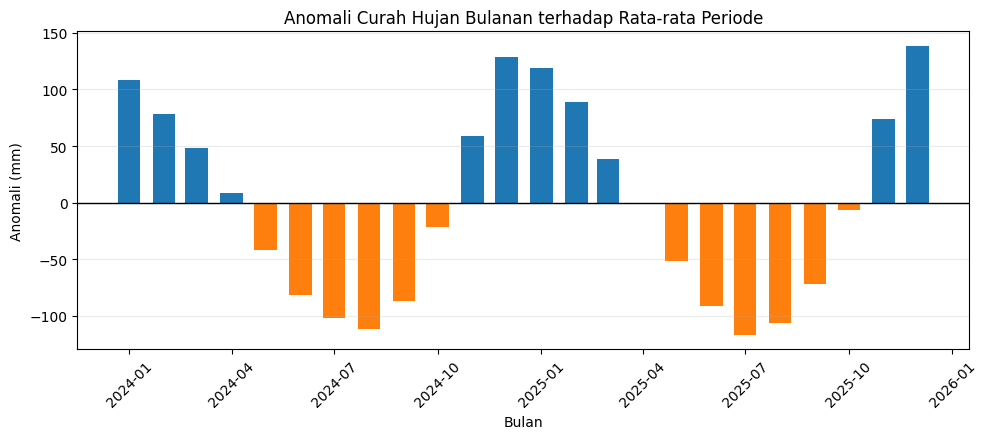

In [5]:
warna = ["tab:blue" if x >= 0 else "tab:orange" for x in df["anomali_mm"]]
plt.figure(figsize=(10, 4.5))
plt.bar(df["bulan"], df["anomali_mm"], color=warna, width=20)
plt.axhline(0, color="black", linewidth=1)
plt.title("Anomali Curah Hujan Bulanan terhadap Rata-rata Periode")
plt.xlabel("Bulan")
plt.ylabel("Anomali (mm)")
plt.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 2.2 Ringkasan hasil recipe sendiri

In [6]:
bulan_terbasah = df.loc[df["curah_hujan_mm"].idxmax()]
bulan_terkering = df.loc[df["curah_hujan_mm"].idxmin()]

print("Bulan dengan hujan tertinggi:")
print(bulan_terbasah["bulan"].strftime("%B %Y"), "-", bulan_terbasah["curah_hujan_mm"], "mm")
print("\nBulan dengan hujan terendah:")
print(bulan_terkering["bulan"].strftime("%B %Y"), "-", bulan_terkering["curah_hujan_mm"], "mm")

assert abs(df["anomali_mm"].mean()) < 1e-10
assert (df["anomali_mm"] >= 0).any() and (df["anomali_mm"] < 0).any()
print("\nCheck berhasil: rata-rata anomali mendekati nol dan ada anomali positif maupun negatif.")

Bulan dengan hujan tertinggi:
December 2025 - 310 mm

Bulan dengan hujan terendah:
July 2025 - 55 mm

Check berhasil: rata-rata anomali mendekati nol dan ada anomali positif maupun negatif.


## 3. Evaluasi singkat

- **Recipe dari buku (R-VIS-001):** berhasil menghasilkan grafik deret waktu yang memiliki judul, label sumbu, unit, dan grid.
- **Recipe buatan sendiri (R-HUJAN-001):** menghitung selisih curah hujan tiap bulan terhadap rata-rata periode, lalu menampilkan anomali positif dan negatif.
- **Pemeriksaan:** assertion memeriksa kelengkapan dan konsistensi dasar data serta hasil perhitungan.
- **Keterbatasan:** data bersifat sintetis. Hasil tidak boleh ditafsirkan sebagai kondisi hujan aktual di suatu wilayah. Untuk penelitian, ganti data contoh dengan observasi/reanalisis dan dokumentasikan sumber, unit, serta periode baseline.

Notebook mengikuti prinsip buku: tentukan problem dan input, hasilkan output yang bisa diperiksa, lalu lakukan check sederhana.